# Testing the effectiveness of fix 0 (frequency conversion by hourly weight)

Fix 0 from [`../../frequency_accounting_improvements.md`](../../frequency_accounting_improvements.md)
changes the hourly frequency ceiling in `compute_hour_limit`: instead of the flat `freq_d/24`,
it uses the weighted `freq_d · w_h`. Here we measure the effect **on a real profile**.

**Why this can be measured without delivery logs.** For one frequency-capped ad with a sufficient
budget, the balancer reduces to `delivered = Σ_h min(cap_h, avail_h)`, where
`avail_h = total · w_h · P` (`prepare_hour_ads`, `corrections.py:184`). Thus the effect is fully
determined by the actual `w_h` (available from the backtest) and the campaign's traffic-to-cap
ratio `R = available_daily_traffic / freq_d`.

**Metric — shortfall against `freq_d`:** `(target − delivered) / target`, where
`target = min(freq_d, available traffic)`. We evaluate the old (`/24`) and new (`·w_h`) formulas.

**Scope.** The model is exact for the isolated case of one frequency-capped ad whose budget or
traffic does not bind before its frequency cap — exactly the example in the documentation.
Multiple ads competing in the LP require separate validation (a full balancer A/B test).

In [ ]:
import glob

import duckdb
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from rtb_sdk.balancer.seasonal.seasonality import _get_h_type, normalize_counts  # noqa: F401

plt.rcParams["figure.figsize"] = (11, 4)
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.3

## Configuration

`PROFILE_FILE` is one **clean** weekly parquet file (default: report-20260615, which passed the
backtest guard). `GRAN` is the frequency-cap granularity (`d`/`w`/`m`). `R_SWEEP` contains
traffic-to-cap ratios. `FREQ` sets the scale and does not affect the resulting proportions.

In [ ]:
MODE = "hour_of_day"
TIMEZONE = "Europe/Moscow"
PROFILE_FILE = "E:/Logs/report-20260615.parquet"   # clean week from the backtest

GRAN = "d"                 # 'd' | 'w' | 'm' -- frequency-cap granularity
FREQ = 10_000.0            # frequency-cap scale (does not affect shortfall proportions)
R_SWEEP = [0.5, 0.75, 1.0, 1.25, 1.5, 2.0, 3.0]   # available traffic / frequency cap

DUCKDB_THREADS = 4
DUCKDB_MEMORY_LIMIT = "8GB"
DUCKDB_TEMP_DIR = "E:/duckdb_tmp"

## Profiles: real (clean week), uniform, and synthetic sharp

`uniform` is a backward-compatibility invariant: the fix must be a no-op.
`sharp` is an artificially peaked profile (half of the daily traffic in one hour), providing
an upper bound on the effect.

In [ ]:
_local_ts = "(datetime AT TIME ZONE '" + TIMEZONE + "')"
if MODE == "hour_of_week":
    HOUR_EXPR = ("((EXTRACT(dow FROM " + _local_ts + ") + 6) % 7) * 24 + "
                 "EXTRACT(hour FROM " + _local_ts + ")")
    N_H = 168
else:
    HOUR_EXPR = "EXTRACT(hour FROM " + _local_ts + ")"
    N_H = 24

con = duckdb.connect()
con.execute(f"PRAGMA threads={DUCKDB_THREADS}")
con.execute(f"PRAGMA memory_limit='{DUCKDB_MEMORY_LIMIT}'")
con.execute(f"PRAGMA temp_directory='{DUCKDB_TEMP_DIR}'")

print(f"Reading profile from {PROFILE_FILE} ...")
agg = con.execute(f"""
    SELECT {HOUR_EXPR} AS h, COUNT(*) AS cnt
    FROM read_parquet('{PROFILE_FILE}')
    GROUP BY h ORDER BY h
""").fetchdf()
_d = {int(h): float(c) for h, c in zip(agg["h"], agg["cnt"])}
w_real = np.array([_d.get(h, 0.0) for h in range(N_H)])
w_real = w_real / w_real.sum()

w_uniform = np.full(N_H, 1.0 / N_H)

# Synthetic sharp profile: half the traffic in one hour, the rest uniformly distributed.
w_sharp = np.full(N_H, 0.5 / (N_H - 1))
w_sharp[N_H // 2] = 0.5


def tv_vs_uniform(w):
    return 0.5 * float(np.sum(np.abs(w - 1.0 / len(w))))


profiles = {"real": w_real, "uniform": w_uniform, "sharp": w_sharp}
for name, w in profiles.items():
    print(f"  {name:>8}: peak={w.max():.4f} (hour {int(w.argmax())}), "
          f"min={w.min():.4f}, TV(w,uniform)={tv_vs_uniform(w):.4f}")

Reading profile from E:/Logs/report-20260615.parquet ...
      real: peak=0.0668 (hour 23), min=0.0236, TV(w,uniform)=0.1415
   uniform: peak=0.0417 (hour 0), min=0.0417, TV(w,uniform)=0.0000
     sharp: peak=0.5000 (hour 12), min=0.0217, TV(w,uniform)=0.4583


## Old and new hourly-cap formulas

`old` is the current implementation (`compute_hour_limit`, flat division independent of the profile).
`new` is fix 0 (`freq · share_h`, where `share_h` follows the documentation table).

In [ ]:
_DAYS_PER_MONTH = 30.44


def hour_cap_old(freq, gran, N_H):
    # Current compute_hour_limit: flat division, identical for all hours.
    div = {"d": 24.0, "w": 24.0 * 7, "m": 24.0 * _DAYS_PER_MONTH}[gran]
    return np.full(N_H, freq / div)


def hour_shares_new(w, gran, mode):
    # Hourly share according to the fix 0 table.
    N_H = len(w)
    if mode == "hour_of_day":
        return {"d": w, "w": w / 7.0, "m": w / _DAYS_PER_MONTH}[gran]
    # hour_of_week
    if gran == "w":
        return w.copy()
    if gran == "m":
        return w * 7.0 / _DAYS_PER_MONTH
    base = np.zeros(N_H)  # gran == 'd': normalize within each day of the week
    for h in range(N_H):
        wd = h // 24
        day_total = w[wd * 24:(wd + 1) * 24].sum()
        base[h] = (w[h] / day_total) if day_total > 0 else 1.0 / 24
    return base


def hour_cap_new(freq, w, gran, mode):
    return freq * hour_shares_new(w, gran, mode)

## Delivery simulation

`avail_h = R · freq · w_h` is the available traffic; `P` cancels out and does not affect proportions.
`delivered = Σ_h min(cap_h, avail_h)`. `target = min(freq, Σ avail_h)`.

In [ ]:
def simulate(w, freq, R, gran="d", mode="hour_of_day"):
    N_H = len(w)
    avail = R * freq * w                      # hourly available traffic (P cancels out)
    cap_old = hour_cap_old(freq, gran, N_H)
    cap_new = hour_cap_new(freq, w, gran, mode)
    d_old = float(np.minimum(cap_old, avail).sum())
    d_new = float(np.minimum(cap_new, avail).sum())
    target = min(freq, float(avail.sum()))
    return {
        "d_old": d_old, "d_new": d_new, "target": target,
        "under_old": (target - d_old) / target if target > 0 else 0.0,
        "under_new": (target - d_new) / target if target > 0 else 0.0,
        "avail": avail, "cap_old": cap_old, "cap_new": cap_new,
    }

## Results: shortfall under the old vs new formula (profile × R)

In [ ]:
rows = []
for pname, w in profiles.items():
    for R in R_SWEEP:
        s = simulate(w, FREQ, R, GRAN, MODE)
        rows.append({
            "profile": pname, "R": R,
            "shortfall_old": s["under_old"],
            "shortfall_new": s["under_new"],
            "eliminated_pp": s["under_old"] - s["under_new"],
        })
res = pd.DataFrame(rows)
res["shortfall_old_%"] = (res["shortfall_old"] * 100).round(2)
res["shortfall_new_%"] = (res["shortfall_new"] * 100).round(2)
res["eliminated_pp"] = (res["eliminated_pp"] * 100).round(2)
res[["profile", "R", "shortfall_old_%", "shortfall_new_%", "eliminated_pp"]]

,profile,R,shortfall_old_%,shortfall_new_%,eliminated_pp
0,real,0.50,0.00,0.0,0.00
1,real,0.75,2.66,0.0,2.66
2,real,1.00,14.15,0.0,14.15
3,real,1.25,6.01,0.0,6.01
4,real,1.50,2.16,0.0,2.16
5,real,2.00,0.00,0.0,0.00
6,real,3.00,0.00,0.0,0.00
7,uniform,0.50,0.00,0.0,0.00
8,uniform,0.75,0.00,0.0,0.00
9,uniform,1.00,0.00,0.0,0.00


## Checking the key identity and invariant

1. **Documentation invariant:** on `uniform`, the fix is a no-op (`old == new`, both shortfalls are 0).
2. **Identity:** at `R = 1`, the old model's shortfall is exactly `TV(w, uniform)`.

In [ ]:
# 1. Invariant: uniform -> the fix changes nothing.
su = simulate(w_uniform, FREQ, 1.0, GRAN, MODE)
assert abs(su["under_old"] - su["under_new"]) < 1e-9, "The fix is NOT a no-op on uniform!"
assert su["under_old"] < 1e-9, "Shortfall on uniform must be 0"
print(f"[OK] uniform: shortfall old={su['under_old']:.6f} == new={su['under_new']:.6f} "
      f"(the fix is a no-op, as documented)")

# 2. Identity: under_old(R=1) == TV(w, uniform).
for pname, w in profiles.items():
    s = simulate(w, FREQ, 1.0, GRAN, MODE)
    tv = tv_vs_uniform(w)
    print(f"[R=1] {pname:>8}: shortfall_old={s['under_old']:.4f}  TV(w,uniform)={tv:.4f}  "
          f"new={s['under_new']:.4f}  match={abs(s['under_old']-tv) < 1e-9}")

[OK] uniform: shortfall old=0.000000 == new=0.000000 (the fix is a no-op, as documented)
[R=1]     real: shortfall_old=0.1415  TV(w,uniform)=0.1415  new=0.0000  match=True
[R=1]  uniform: shortfall_old=0.0000  TV(w,uniform)=0.0000  new=0.0000  match=True
[R=1]    sharp: shortfall_old=0.4583  TV(w,uniform)=0.4583  new=0.0000  match=True


## Charts

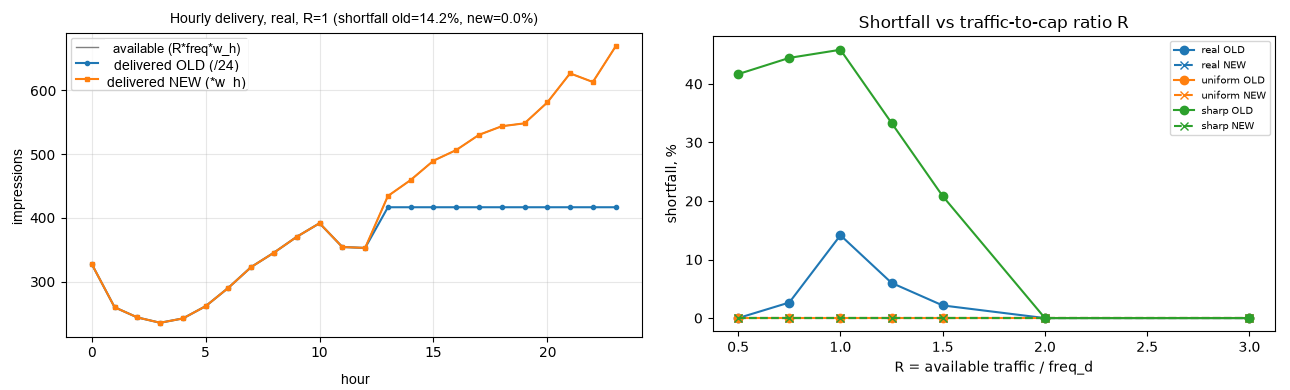

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

# Left: hourly delivery old vs new vs available, real profile, R=1.
s = simulate(w_real, FREQ, 1.0, GRAN, MODE)
x = np.arange(N_H)
axes[0].plot(x, s["avail"], color="grey", lw=1, label="available (R·freq·w_h)")
axes[0].plot(x, np.minimum(s["cap_old"], s["avail"]), marker="o", ms=3,
             label="delivered OLD (/24)")
axes[0].plot(x, np.minimum(s["cap_new"], s["avail"]), marker="s", ms=3,
             label="delivered NEW (·w_h)")
axes[0].set_title(f"Hourly delivery, real, R=1 "
                  f"(shortfall old={s['under_old']*100:.1f}%, new={s['under_new']*100:.1f}%)")
axes[0].set_xlabel("hour"); axes[0].set_ylabel("impressions"); axes[0].legend(fontsize=8)

# Right: shortfall vs R for each profile (old solid, new dashed).
for pname, w in profiles.items():
    uo = [simulate(w, FREQ, R, GRAN, MODE)["under_old"] * 100 for R in R_SWEEP]
    un = [simulate(w, FREQ, R, GRAN, MODE)["under_new"] * 100 for R in R_SWEEP]
    line, = axes[1].plot(R_SWEEP, uo, marker="o", label=f"{pname} OLD")
    axes[1].plot(R_SWEEP, un, marker="x", ls="--", color=line.get_color(),
                 label=f"{pname} NEW")
axes[1].set_title("Shortfall against freq_d vs traffic-to-cap ratio R")
axes[1].set_xlabel("R = available traffic / freq_d")
axes[1].set_ylabel("shortfall, %")
axes[1].legend(fontsize=7)

plt.tight_layout()
plt.show()

## Interpretation and conclusions

- **The new formula (the fix) gives zero shortfall for every R:** it always delivers
  `min(freq_d, available)`, because the hourly cap follows the shape of the traffic.
- **The old formula underdelivers when the frequency cap is comparable to traffic** (`R ~ 0.5-1.7`):
  during peak hours, the flat `freq_d/24` cap throttles delivery (below `freq_d·w_h`), while
  quiet hours provide no traffic from which to recover the reserve. At `R = 1`, shortfall = `TV(w, uniform)`.
- **On `uniform`, the fix changes nothing** (the documentation invariant): its effect is strictly
  proportional to the profile's nonuniformity.
- **Who benefits:** campaigns with daily/weekly frequency caps comparable to available traffic
  (`R` is not large). At a large `R`, both formulas deliver in full and the fix is a no-op.
- **Limitation:** this is an isolated single-ad case. Multiple ads competing for traffic in the LP
  require a full balancer A/B test (the next step).